In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

PRIMARY_COLOR = "#2563EB"   
ACCENT_COLOR = "#0D9488"   
EDGE_COLOR = "#1E293B"      
GRID_COLOR = "#CBD5E1"     

plt.rcParams["axes.edgecolor"] = EDGE_COLOR
plt.rcParams["axes.linewidth"] = 0.8


data_path = Path("../data/employees.csv")
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path)
df["city_clean"] = df["city"].astype(str).str.strip().str.title()

print("Rows loaded:", len(df))
print(df)

Rows loaded: 5
   id     name       city  salary city_clean
0   1     Arun    Chennai   65000    Chennai
1   2    Meera  Bengaluru   72000  Bengaluru
2   3  Karthik    chennai   58000    Chennai
3   4    Divya  Hyderabad   68000  Hyderabad
4   5    Rohan    CHENNAI   81000    Chennai


## 1. Bar Chart: Salary by Employee

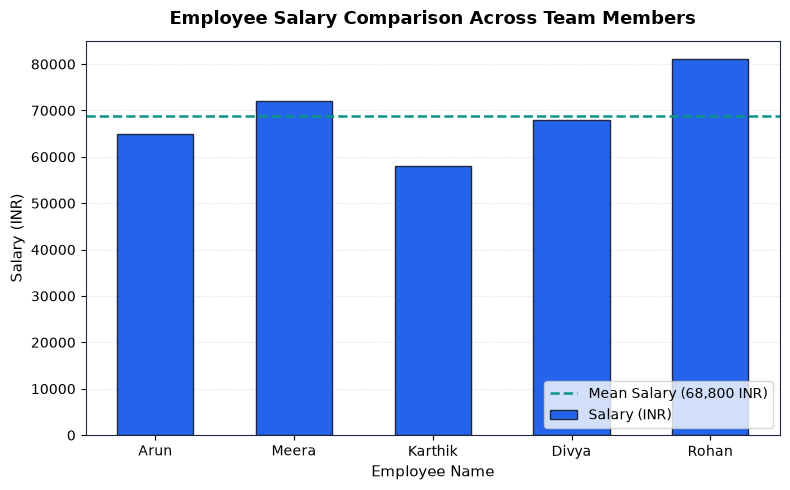

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    df["name"],
    df["salary"],
    color=PRIMARY_COLOR,
    edgecolor=EDGE_COLOR,
    width=0.55,
    label="Salary (INR)"
)

mean_salary = df["salary"].mean()
ax.axhline(
    mean_salary,
    color=ACCENT_COLOR,
    linestyle="--",
    linewidth=1.8,
    label=f"Mean Salary ({mean_salary:,.0f} INR)"
)

ax.set_title("Employee Salary Comparison Across Team Members", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Employee Name", fontsize=11)
ax.set_ylabel("Salary (INR)", fontsize=11)
ax.grid(axis="y", linestyle=":", color=GRID_COLOR, alpha=0.8)
ax.set_axisbelow(True)
ax.legend(loc="lower right")

plt.tight_layout()
fig.savefig(figures_dir / "01_bar_salary_by_employee.png", dpi=300)
plt.show()

**Insight:** Individual salaries vary around the 68,800 INR team average, with top earners sitting above the reference line and lower earners below it.

## 2. Histogram: Salary Distribution

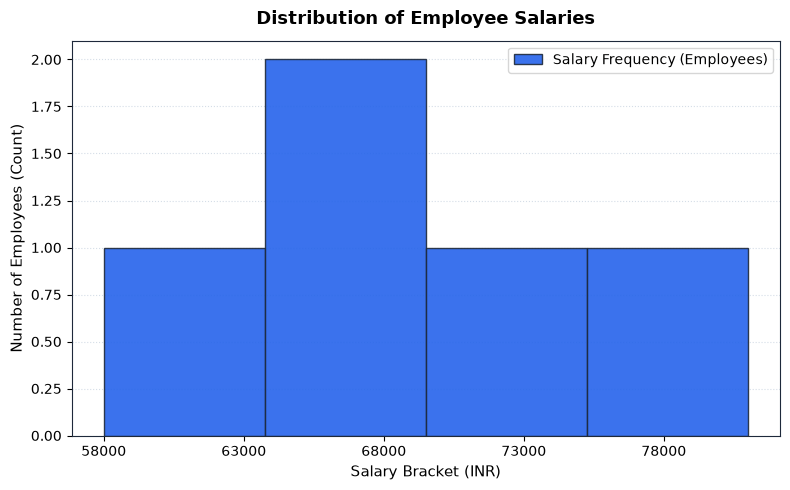

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    df["salary"],
    bins=4,
    color=PRIMARY_COLOR,
    edgecolor=EDGE_COLOR,
    alpha=0.9,
    label="Salary Frequency (Employees)"
)

ax.set_title("Distribution of Employee Salaries", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Salary Bracket (INR)", fontsize=11)
ax.set_ylabel("Number of Employees (Count)", fontsize=11)
ax.set_xticks([58000, 63000, 68000, 73000, 78000])
ax.grid(axis="y", linestyle=":", color=GRID_COLOR, alpha=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper right")

plt.tight_layout()
fig.savefig(figures_dir / "02_histogram_salary_distribution.png", dpi=300)
plt.show()

**Insight:** Most employees cluster in the middle-to-upper salary range rather than piling up at a single extreme, showing a relatively compact spread across the small sample.

## 3. Scatter Plot: Employee ID vs. Salary

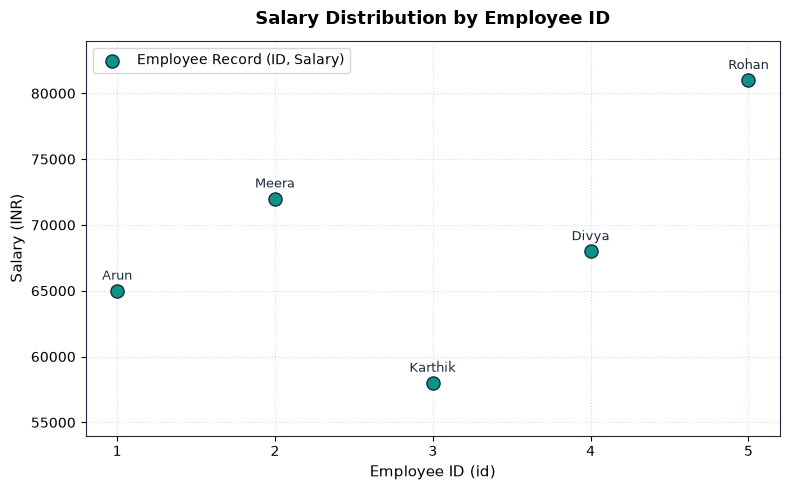

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df["id"],
    df["salary"],
    color=ACCENT_COLOR,
    edgecolor=EDGE_COLOR,
    s=90,
    zorder=3,
    label="Employee Record (ID, Salary)"
)

for _, row in df.iterrows():
    ax.annotate(
        row["name"],
        (row["id"], row["salary"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        color=EDGE_COLOR
    )

ax.set_title("Salary Distribution by Employee ID", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Employee ID (id)", fontsize=11)
ax.set_ylabel("Salary (INR)", fontsize=11)
ax.set_xticks(df["id"])
ax.set_ylim(54000, 84000)
ax.grid(True, linestyle=":", color=GRID_COLOR, alpha=0.8)
ax.legend(loc="upper left")

plt.tight_layout()
fig.savefig(figures_dir / "03_scatter_id_vs_salary.png", dpi=300)
plt.show()

**Insight:** Higher employee IDs do not automatically correspond to higher salaries, indicating that pay is not strictly sequential by ID order.

## 4. Line Chart: Sorted Salary Progression

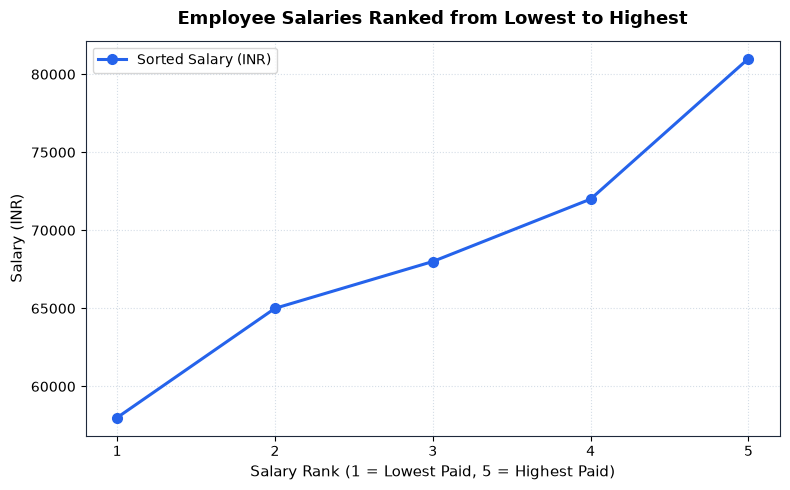

In [5]:
df_sorted = df.sort_values("salary", ascending=True).reset_index(drop=True)
df_sorted["rank"] = df_sorted.index + 1

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df_sorted["rank"],
    df_sorted["salary"],
    color=PRIMARY_COLOR,
    marker="o",
    markersize=7,
    linewidth=2.2,
    label="Sorted Salary (INR)"
)

ax.set_title("Employee Salaries Ranked from Lowest to Highest", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Salary Rank (1 = Lowest Paid, 5 = Highest Paid)", fontsize=11)
ax.set_ylabel("Salary (INR)", fontsize=11)
ax.set_xticks(df_sorted["rank"])
ax.grid(True, linestyle=":", color=GRID_COLOR, alpha=0.8)
ax.legend(loc="upper left")

plt.tight_layout()
fig.savefig(figures_dir / "04_line_sorted_salaries.png", dpi=300)
plt.show()

**Insight:** Sorting salaries from lowest to highest reveals a steady step-up across ranks with a total spread of roughly 20,000 INR between the lowest and highest earners.

## 5. Box Plot: Salary Spread and Quartiles

C:\Users\ricky\AppData\Local\Temp\ipykernel_3508\3081279061.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(


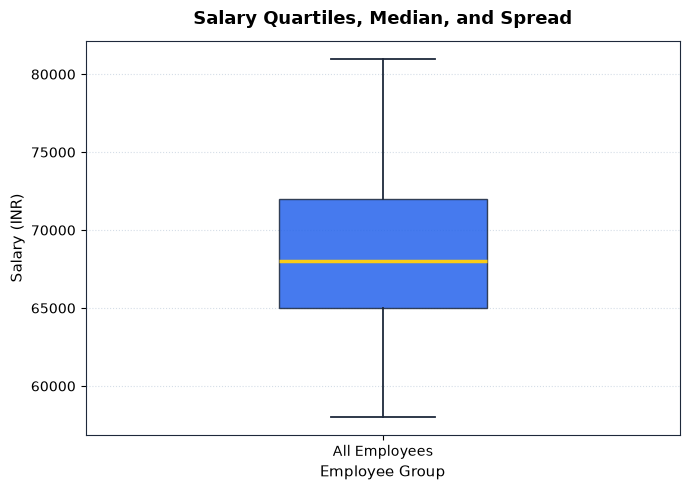

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))

box = ax.boxplot(
    df["salary"],
    vert=True,
    patch_artist=True,
    widths=0.35,
    tick_labels=["All Employees"],
    boxprops=dict(facecolor=PRIMARY_COLOR, color=EDGE_COLOR, alpha=0.85),
    medianprops=dict(color="#FACC15", linewidth=2.5),
    whiskerprops=dict(color=EDGE_COLOR, linewidth=1.3),
    capprops=dict(color=EDGE_COLOR, linewidth=1.3),
    flierprops=dict(marker="o", markerfacecolor=ACCENT_COLOR, markeredgecolor=EDGE_COLOR, markersize=7)
)

ax.set_title("Salary Quartiles, Median, and Spread", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Employee Group", fontsize=11)
ax.set_ylabel("Salary (INR)", fontsize=11)
ax.grid(axis="y", linestyle=":", color=GRID_COLOR, alpha=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
fig.savefig(figures_dir / "05_boxplot_salary_spread.png", dpi=300)
plt.show()

**Insight:** The box plot shows the median and interquartile range clearly with no extreme outliers, confirming a tight central compensation band for this 5-row dataset.